In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import $Q$-vectors, Thrust

In [2]:
labels = {'Z': r'$Z\to q\bar q$', 
          'Z1': r'$Z\to q\bar q$, 1 splitting', 
        #   'Z2': r'$Z\to q\bar q$, 2 splittings',
        #   'Z3': r'$Z\to q\bar q$, 3 splittings', 'Z4': r'$Z\to q\bar q$, 4 splittings',
          'Z1_500GeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          'Z1_fix05': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.05$',
          'Z1_fix50': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.50$',
          }

In [3]:
#########################################################
### Load features (computed in make_features.ipynb)
#########################################################

QVC_sets = {k: np.load(f'features/QVEC_nq2048_{k}.npy', mmap_mode='r') for k in labels if os.path.exists(f'features/QVEC_nq2048_{k}.npy')}
print('Qvc:', {k: v.shape for k, v in QVC_sets.items()}, '  missing:', [k for k in labels if k not in QVC_sets])

#########################################################
### Load targets (computed in Make_Features.ipynb)
#########################################################
thrusts = {k: np.load(f'features/TARGETS_{k}.npz')['thrust'] for k in labels if os.path.exists(f'features/TARGETS_{k}.npz')}
print('thrust:', {k: v.shape for k, v in thrusts.items()}, '  missing:', [k for k in labels if k not in thrusts])

Qvc: {'Z': (100000, 2048), 'Z1': (99387, 2048), 'Z1_500GeV': (100000, 2048), 'Z1_1TeV': (99999, 2048), 'Z1_fix08': (73394, 2048), 'Z1_fix12': (86070, 2048), 'Z1_fix16': (92872, 2048), 'Z1_fix05': (28793, 2048), 'Z1_fix50': (49989, 2048)}   missing: []
thrust: {'Z': (100000,), 'Z1': (99387,), 'Z1_500GeV': (100000,), 'Z1_1TeV': (99999,), 'Z1_fix08': (73394,), 'Z1_fix12': (86070,), 'Z1_fix16': (92872,), 'Z1_fix05': (28793,), 'Z1_fix50': (49989,)}   missing: []


## Measure $r$

In [4]:
def target_power(X, y, depth=1, M=None, seed=0, chunk=5000, dev=None):
    """NTK Gram eigenvalues lam_k and target power v2_k = w̄_k² η_k = (U^T y)_k² / M  (Σ_k v2 = mean(y²)). """
    dev = dev or ('cuda' if torch.cuda.is_available() else 'cpu')
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(y), min(M, len(y)), replace=False)) if M is not None else np.arange(len(y))
    X = preprocess(np.asarray(X[idx], dtype=np.float64))  # standardizes and normalizes (puts on unit sphere, so NTK results are consistent... )
    y = np.asarray(y[idx], dtype=np.float64); 
    y = y - y.mean()
    X = torch.as_tensor(X, device=dev); 
    N = len(X); 
    K = torch.empty((N, N), dtype=torch.float64, device=dev)
    for i in range(0, N, chunk): K[i:i+chunk] = ntk(X[i:i+chunk], X, depth)
    K /= N
    lam, U = torch.linalg.eigh(K); 
    lam, U = lam.flip(0).cpu().numpy(), U.flip(1).cpu().numpy()
    del K, X; torch.cuda.empty_cache()
    return lam, (U.T @ y)**2/N

In [ ]:
M, depth, seeds = 20_000, 4, np.arange(0,20)
for key in labels:
    if key not in QVC_sets or key not in thrusts: continue
    t0 = time.time()
    out = [target_power(QVC_sets[key], thrusts[key], depth=depth, M=M, seed=s) for s in seeds]
    lam, v2 = np.mean([o[0] for o in out], axis=0), np.mean([o[1] for o in out], axis=0)
    np.save(f'spectra/TARGETPOWER_NTK_d{depth}_Q_nq2048_M{M}_nseeds{len(seeds)}_{key}.npy', np.stack([lam, v2]))
    print(f'{key:>10}: done in {time.time() - t0:.0f} s')

r = 0.53


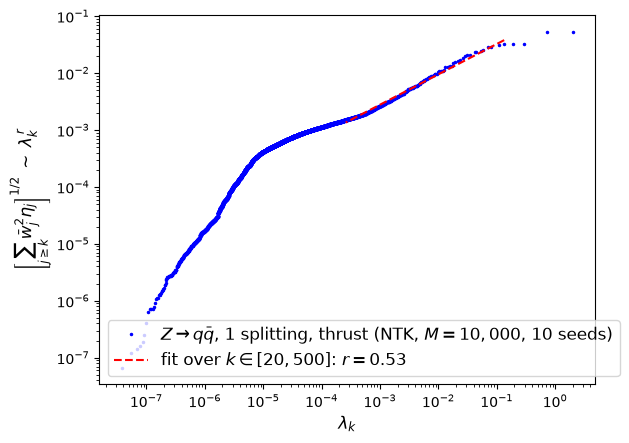

In [20]:
key = 'Z1'

lam, v2 = np.load(f'spectra/TARGETPOWER_NTK_d{depth}_Q_nq2048_M{M}_nseeds20_{key}.npy')

k = np.arange(1, len(lam) + 1); 
tail = np.cumsum(v2[::-1])[::-1];  ## reverse it to sum j > k, then reverse it back ... 
# mask = (k >= 1) & (k <= len(k)//10)
mask = (k >= 5) & (k <= 500)
fit = np.polyfit(np.log(lam[mask]), np.log(np.sqrt(tail[mask])), 1); 
print(f'r = {fit[0]:.2f}')


plt.loglog(lam, np.sqrt(tail), '.', ms=3, color='b', label=rf'{labels[key]}, thrust (NTK, $M = {M:,}$, 10 seeds)')
plt.loglog(lam[mask], np.exp(np.polyval(fit, np.log(lam[mask]))), 'r--', label=rf'fit over $k \in [20, 500]$: $r = {fit[0]:.2f}$')
plt.xlabel(r'$\lambda_k$', fontsize=12);
plt.ylabel(r'$\left[\sum_{j\geq k} \bar w_j^2\eta_j\right]^{1/2} \;\sim\; \lambda_k^{\,r}$', fontsize=12);
plt.legend(fontsize=12)